# 13-强化学习入门


## 1. 什么是强化学习

本篇依据课程《具身智能-强化学习》的 **9 页 PPT** 整理，按照课件顺序介绍强化学习的组成、状态与动作、奖励、策略，最后用冰冻湖案例串起这些概念。

**强化学习（Reinforcement Learning，RL）**是一种通过智能体与环境交互，以最大化长期累计奖励为目标的学习方法。

理解这个定义，要抓住三个相连的过程：智能体作出选择，环境给出反馈，智能体利用交互经验学习怎样选择。目标关注的是一段过程的累计收益，而不只是某一步得到的奖励。

课件强调，强化学习用于在动态、复杂的环境中寻找较好的决策，常见应用包括机器人、游戏 AI 和推荐系统。这里的“最佳决策”是学习目标，不能理解为使用强化学习就一定能找到最优解。

本课是概念入门，没有给出训练代码、算法更新公式、运行命令或机械臂实机实验步骤。


## 2. 强化学习的五个组成部分

课件第 3 页先区分谁在做决策、与什么交互，以及一次交互涉及哪些信息。

| 组成部分 | 英文 | 含义 |
|---|---|---|
| 智能体 | Agent | 学习者和决策者，负责选择动作 |
| 环境 | Environment | 智能体交互的外界，动作会对它产生影响 |
| 动作 | Action | 智能体作出的选择，以及对环境施加的影响 |
| 状态 | State | 描述当前环境情况的信息 |
| 奖励 | Reward | 用于指导学习的反馈信号 |

### 2.1 课件示例：小孩子选择食物

课件把“小孩子吃饭”抽象成一个强化学习问题：

| 组成部分 | 对应内容 |
|---|---|
| 智能体 | 小孩子 |
| 环境 | 餐桌上的食物，包括蔬菜、米饭、零食 |
| 动作 | 选择吃蔬菜、吃米饭或吃零食 |
| 状态 | 当前盘子里剩下的食物 |
| 奖励 | 吃蔬菜 `+2`，吃米饭 `+1`，吃零食 `-2` |

这个例子的重点是区分各部分的职责。例如，“吃蔬菜”是动作，“盘子里还有哪些食物”是状态，“吃完得到 +2”是奖励。三者不能混为一谈。

**示例边界：**这里的奖励数值是课件为解释概念而设定的规则，不是食物本身自带的数值。课件也没有给出食物数量、一次吃多少或何时结束等完整环境规则。


## 3. 状态、动作与奖励怎样构成循环

课件第 4 页给出的顺序是：

```text
状态 → 动作 → 奖励 → 新状态
```

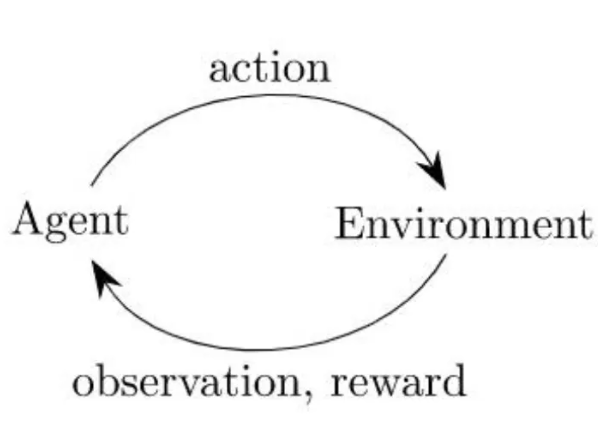

图中 `Agent` 指智能体，`Environment` 指环境，`action` 指动作，`observation, reward` 指观测与奖励。按图中的箭头理解，一次交互可以分为：

1. 智能体获得当前环境的信息。
2. 智能体根据这些信息选择并执行动作。
3. 环境发生变化，返回奖励以及新的观测。
4. 智能体依据新的信息继续选择动作，形成连续交互。

沿用吃饭例子：先看到盘子里剩下的食物，再选择吃蔬菜，按课件规则得到 `+2`，随后盘子里剩余食物发生变化，成为下一次选择的依据。

**术语补充：**原图写的是“观测（observation）”，正文使用“状态（state）”。观测是智能体实际能获得的信息，未必包含完整状态；本课为入门采用简化描述。文字中的箭头用于表达交互顺序，不表示奖励必须先于新状态单独返回。


## 4. 状态：描述当前处在什么情况

课件第 5 页将状态定义为：某一时刻环境或事物的样子和情况的描述。它为智能体选择动作提供依据。

| 应用 | 课件中的状态示例 |
|---|---|
| 游戏 AI | 下棋时棋盘上的布局 |
| 自动驾驶 | 路上的车流、人行道和红绿灯的情况 |

同一个动作放到不同状态下，可能产生不同结果。例如，棋盘布局改变后，可落子的位置和落子的效果也会改变，因此决策需要依赖当前信息。

**补充辨析：**表格只是直观示例，不是完整的状态设计。实际下棋还可能需要知道轮到谁、规则所需的历史信息；驾驶任务也可能需要速度等信息。不能把课件列出的少数例子直接当作所有任务都足够的状态字段。


## 5. 动作：离散选择与连续取值

课件第 6 页把动作定义为智能体在特定状态下作出的选择，并区分离散动作与连续动作。可选择的全部动作构成**动作空间（action space）**。

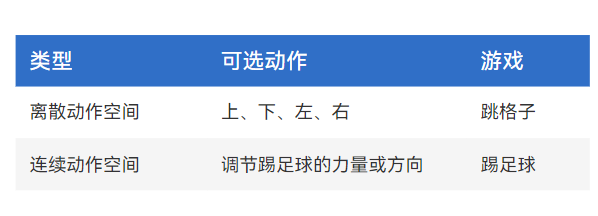

| 类型 | 本课中的理解 | 课件例子 |
|---|---|---|
| 离散动作 | 从若干个分开的选项中选择 | 跳格子时选择上、下、左、右 |
| 连续动作 | 在连续数值范围内选择取值 | 方向盘角度，或踢足球的力量与方向 |

“选择向左”是在选动作类别；“把方向盘转到某个角度”是在选一个数值。它们的区别在于动作如何表示。

**措辞补充：**课件用“有限选择”和“无限选择”作入门对比。连续动作的取值可以有上下限，“无限”指理想数学模型中区间内有无限多个可选值，不表示方向盘可以无限转动。离散动作在本课例子中是有限个，一般概念也可以包含可数的动作集合。


## 6. 奖励：用反馈引导长期行为

课件第 7 页将奖励解释为：智能体完成动作后获得的反馈，用来告诉它这个动作是“好”还是“不好”。正向反馈可以鼓励行为，负向反馈可以抑制行为。

奖励有两个作用：

- 引导智能体倾向于符合任务目标的行为。
- 帮助智能体优化长期回报，逐步学会怎样完成目标。

这里要区分**一次奖励**与**长期回报**：奖励是交互中获得的一次反馈；长期回报关注连续多个步骤带来的累计收益。某一步奖励较高，并不意味着后续结果一定更好。

吃饭例子中的 `+2`、`+1`、`-2` 是三类动作对应的反馈。它们表达的是这个示例的偏好；其他任务需要根据自己的目标确定奖励规则。

**补充辨析：**奖励反映设定的任务目标，并不是对动作绝对“正确”或“错误”的判断。一个中间动作也可能暂时没有奖励，却是之后完成目标所必需的步骤。课件没有进一步给出长期回报的计算公式。


## 7. 策略：根据状态决定怎样行动

课件第 8 页定义：**策略（Policy）是智能体根据状态选择动作的规则。**状态告诉智能体当前处在什么情况，策略规定在这种情况下怎样选择。

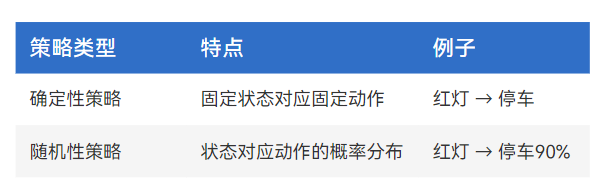

| 策略类型 | 含义 | 课件原例 |
|---|---|---|
| 确定性策略 | 对于给定状态，选择一个确定的动作 | 红灯 → 停车 |
| 随机性策略 | 对于给定状态，给出各个动作的概率，并按概率选择 | 红灯 → 停车 90% |

确定性策略不等于在所有状态下都执行同一个动作，而是对**同一个状态**给出确定选择。随机性策略也不是毫无规则地行动，它用概率分布描述如何选择。

**原例说明：**“停车 90%”只展示了一个动作的概率，其余 `10%` 对应什么动作，课件没有说明。一个完整的离散动作概率分布需要覆盖所有可选动作，概率非负且总和为 `1`。这张表用于说明策略分类，没有提供可直接使用的交通控制方案。

**补充辨析：**随机性策略说的是“选择动作时有随机性”。动作执行后，环境是否一定按预期变化，是另一个问题；两者不能直接等同。


## 8. 冰冻湖案例：把各个概念连起来

课件第 9 页提出任务：一个智能体需要穿过冰冻湖，避开水洞，拿到终点的宝藏。

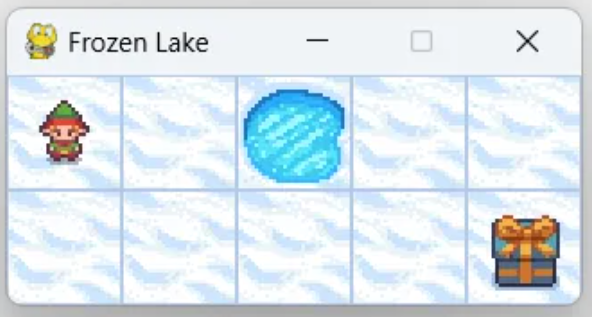

原图是一个 **2 行 5 列**的网格。探险家在左上角，水洞在上排第 3 格，宝藏在右下角。可以用这个地图直观理解状态与动作怎样对应。

| 要素 | 冰冻湖中的对应内容 |
|---|---|
| 智能体 | 探险家 |
| 环境 | 由冰面、水洞和终点组成的湖面网格 |
| 状态 | 探险家当前所在的网格位置 |
| 动作 | 选择向上、下、左、右移动到相邻网格 |
| 奖励 | 成功到达终点得到 `+1` 分 |
| 策略 | 根据当前位置决定移动方向，目标是避免掉水并尽快到达终点 |

### 8.1 一次选择怎样影响后续选择

假设探险家从左上角选择向下，且环境确实让它向下移动，那么新状态就是左下角。下一步应根据这个新位置重新决定方向，而不是继续按出发时的状态作判断。

这段读图说明对应前面的交互循环：当前位置提供决策依据，动作影响位置，环境给出反馈，智能体根据新位置继续行动。它不是课件的训练代码或实际运行结果。

### 8.2 奖励规则与任务描述的边界

课件明确给出的奖励只有“成功到达终点：`+1`”。普通移动、掉入水洞、撞到边界各自有什么奖励，以及是否存在打滑、步数上限，课件没有规定。

> **补充辨析：**任务描述写了“尽快到达终点”，但仅有终点 `+1` 并不能单独表达对更短路径的偏好。如果不同路线都成功到达、途中均为 `0` 奖励，且累计奖励不考虑时间因素，那么这些路线的累计奖励相同。不能只凭这一条奖励规则就断言学到的策略一定走最短路线。

本案例用于辨认强化学习的基本要素。课件没有提供具体训练算法、完整环境配置、最优路径、训练次数或成功率，因此这里保留概念与地图解读，不补写未经资料支持的实验结果。
